In [1]:
import matplotlib.pyplot as plt
import pandas as pd

crop_df = pd.read_csv(r"C:\Users\Aaish\Downloads\crop_yield.csv")

In [2]:

crop_df = crop_df.dropna(subset=["YIELD_KG"])

In [4]:
crop_df["AREA_ACRES"] = crop_df["AREA_ACRES"].fillna(
    crop_df["AREA_ACRES"].mean()
)

In [5]:

crop_df["DISTRICT"] = crop_df["DISTRICT"].fillna("Unknown")


In [6]:
crop_df["FERTILIZER_USED"] = crop_df["FERTILIZER_USED"].fillna("No")

In [7]:
crop_df["YIELD_VALUE"] = crop_df["YIELD_VALUE"].fillna(
    crop_df["YIELD_VALUE"].mean()
)

In [8]:
crop_df["HARVEST_DATE"] = pd.to_datetime(
    crop_df["HARVEST_DATE"], format="%d/%m/%Y", errors="coerce"
)

In [9]:
crop_df["FARM_ID"] = crop_df["FARM_ID"].str.replace("F", "").astype(int)

In [10]:
date_pivot = crop_df.pivot_table(
    values="YIELD_KG", index="HARVEST_DATE", aggfunc="sum"
)
print(date_pivot)

              YIELD_KG
HARVEST_DATE          
2023-01-01      1500.0
2023-01-02      1500.0
2023-01-03      2500.0
2023-01-04      1500.0
2023-01-05      1500.0
...                ...
2031-03-15      1500.0
2031-03-16      2000.0
2031-03-17      2000.0
2031-03-18      2000.0
2031-03-19      2500.0

[2670 rows x 1 columns]


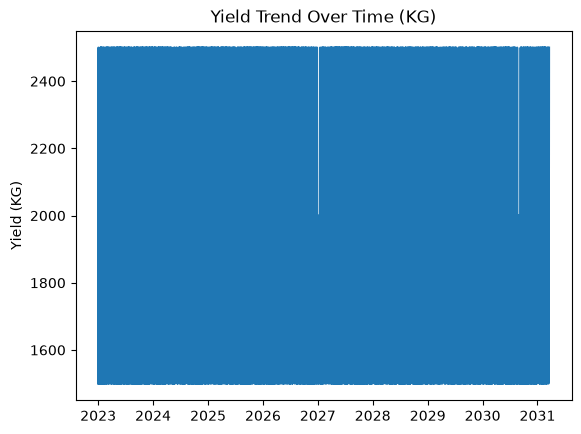

In [11]:
import matplotlib.pyplot as plt

plt.plot(date_pivot.index, date_pivot["YIELD_KG"])
plt.title("Yield Trend Over Time (KG)")
plt.ylabel("Yield (KG)")
plt.savefig("crop_yield_trend.png", dpi=300, bbox_inches="tight")
plt.show()